Imports and configuration: libraries, DATA_DIR, VALID_EXT, and IMG_SIZE = 224 as constants at the top so you can change them in one place.

Explore the dataset: class names, number of images per class.

Check and clean extensions: count extensions, list bad_files, review them, then delete.

Inspect one image: shape, dtype, min/max, and display it.

Load images and labels (try/except): two lists, images and labels.

Resize to 224x224 with OpenCV (done inside the loading loop).

Shuffle images and labels together.

Convert to NumPy arrays and print shapes and dtypes.

Save the arrays to disk (we’ll do this at the end of Day 1).

In [30]:
import os
from collections import Counter

DATA_DIR = "/app/data"
VALID_EXT = (".jpeg", ".jpg", ".bmp", ".png")
list_bad_files = {}
for class_name in os.listdir(DATA_DIR):
    class_path = os.path.join(DATA_DIR, class_name)
    ext_counter = Counter()
    # bad_file = Counter()
    for file in os.listdir(class_path):
        ext = os.path.splitext(file)[1].lower() 
        if ext not in VALID_EXT :
            # bad_file[ext] +=1
            list_bad_files.setdefault(class_name,[]).append(file)
        else:
            ext_counter[ext] += 1
    print(class_name, dict(ext_counter))
print(list_bad_files)


print('start delete bad files')

deleted = 0
for class_name, files in list_bad_files.items():
    for file in files:
        path = os.path.join(DATA_DIR, class_name, file)
        if os.path.isfile(path):
            print("delete file named :", file)
            os.remove(path)
            deleted += 1

glioma {'.jpg': 1621}
meningioma {'.jpg': 1645}
notumor {'.jpg': 2000}
pituitary {'.jpg': 1757}
{'meningioma': ['dhghfsfq.txt']}
start delete bad files
delete file named : dhghfsfq.txt


image shap: (512, 512, 3)
Data type: uint8
Min: 0
Max: 255


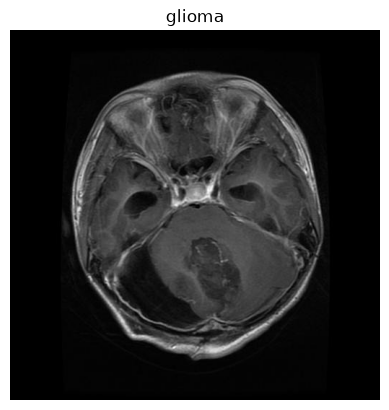

In [66]:
import cv2
import matplotlib.pyplot as plt

first_class = os.listdir(DATA_DIR)[0]
# print(first_class)
class_folder_path = os.path.join(DATA_DIR,first_class)
path_first_image = os.path.join(class_folder_path,os.listdir(class_folder_path)[0])
# print(path_first_image)
image = cv2.imread(path_first_image)

# print(image)

print("image shap:", image.shape)
print("Data type:", image.dtype)
print("Min:", image.min())
print("Max:", image.max())


image_rgb = cv2.cvtColor(image,cv2.COLOR_BGR2RGBA)


plt.imshow(image_rgb)
plt.title(first_class)
plt.axis("off")
plt.show()


--- Image 1 ---
Class name: meningioma
Shape: (512, 512, 3)
Data Type: uint8
Minimum pixel: 0
Maximum pixel: 251

--- Image 2 ---
Class name: glioma
Shape: (512, 512, 3)
Data Type: uint8
Minimum pixel: 0
Maximum pixel: 254

--- Image 3 ---
Class name: notumor
Shape: (225, 225, 3)
Data Type: uint8
Minimum pixel: 0
Maximum pixel: 255

--- Image 4 ---
Class name: meningioma
Shape: (512, 512, 3)
Data Type: uint8
Minimum pixel: 0
Maximum pixel: 253

--- Image 5 ---
Class name: pituitary
Shape: (512, 512, 3)
Data Type: uint8
Minimum pixel: 0
Maximum pixel: 254



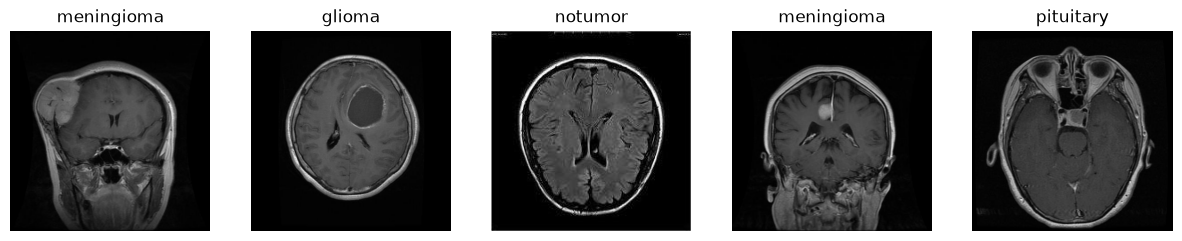

In [67]:
import random

dataset_path = "path/to/your/dataset"

all_folders = os.listdir(DATA_DIR)

plt.figure(figsize=(15, 4))

for i in range(5):
    
    random_class = random.choice(all_folders)
    class_folder_path = os.path.join(DATA_DIR, random_class)
    
    all_images = os.listdir(class_folder_path)
    random_image_name = random.choice(all_images)
    
    image_path = os.path.join(class_folder_path, random_image_name)
    
    image = cv2.imread(image_path)
    
    if image is None:
        print("Error: Could not load", image_path)
    else:
        print("--- Image", i + 1, "---")
        print("Class name:", random_class)
        print("Shape:", image.shape)
        print("Data Type:", image.dtype)
        print("Minimum pixel:", image.min())
        print("Maximum pixel:", image.max())
        print()
        
        image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        plt.subplot(1, 5, i + 1) 
        
        plt.imshow(image_rgb)
        plt.title(random_class)
        plt.axis("off")

plt.show()

In [69]:
import numpy as np

images = []
labels = []
failed = []

for class_name in sorted(all_folders) :
    class_path = os.path.join(DATA_DIR,class_name)
    
    if not os.path.isdir(class_path) :
        continue
    
    for file in os.listdir(class_path):
        file_path = os.path.join(class_path,file)
        
        
        try :
            image = cv2.imread(file_path)
            image = cv2.resize(image,(224,224))
            
            images.append(image)
            labels.append(class_name)        
        except Exception as e:
            failed.append(file_path)
            print(f"error : {file_path} ==> {e}")
            
    print(f"{class_name} is done ")
    
    
print("-"*100)

print("Loaded:", len(images))
print("Failed:", len(failed))
print("Same length:", len(images) == len(labels))
print("First label:", labels[0])
print("First image shape:", images[0].shape)
    

glioma is done 
meningioma is done 
notumor is done 
pituitary is done 
----------------------------------------------------------------------------------------------------
Loaded: 7023
Failed: 0
Same length: True
First label: glioma
First image shape: (224, 224, 3)


In [71]:
from sklearn.utils import shuffle

images_shuffle,labels_shuffle  = shuffle(images,labels,random_state=42)


images_shuffle_np_array = np.array(images_shuffle)
labels_shuffle_np_array = np.array(labels_shuffle)


print("images info : ")
print("shape : ",images_shuffle_np_array.shape)
print("Type : ",images_shuffle_np_array.dtype)

print("labels info : ")
print("shape : ",labels_shuffle_np_array.shape)
print("Type : ",labels_shuffle_np_array.dtype)


SAVE_FOLDER = "/app/data/processed"

os.makedirs(SAVE_FOLDER,exist_ok=True)

SAVE_PATH = os.path.join(SAVE_FOLDER,"dataset.npz")

print("Start Save dataset into : ", SAVE_PATH)
np.savez_compressed(SAVE_PATH,images=images_shuffle_np_array,labels=labels_shuffle_np_array)

print("Done")


images info : 
shape :  (7023, 224, 224, 3)
Type :  uint8
labels info : 
shape :  (7023,)
Type :  <U10
Start Save dataset into :  /app/data/processed/dataset.npz
Done
